# 01: Model description

A first look at evoparam: build one evoked response whose parts we know, fit it, and
check that the fit gives those parts back.

evoparam describes an evoked response (the average of the signal of one recording
contact over many stimulations, time-locked to the stimulus) as

$$y(t) = b(t) + \sum_{k=1}^{K} A_k \, s_k(t; \theta_k) + \varepsilon(t)$$

- $y(t)$ is the averaged signal of one contact, in microvolts (µV), at time
  $t$ after the stimulus.
- $b(t)$ is the **background**: the slow part that is not a response, for example
  the recovery of the amplifier after a stimulation pulse. It plays the role that the
  aperiodic (1/f) part plays in a power spectrum.
- Each $s_k$ is a **component**: a bump of a known shape (here a Gaussian bell) with
  a height of 1, a peak time (**latency**, ms) and a width (**FWHM**, full width at half
  maximum, ms). $A_k$ is its **amplitude** in µV, negative for a downward bump (N1,
  N2). Components play the role that the periodic peaks play in a power spectrum.
- $\varepsilon(t)$ is the **noise**: what is left, measured on the pre-stimulus
  baseline.

The number of components $K$ is not given by the user: components are added one at
a time and kept only when the BIC (Bayesian information criterion, a score that rewards a
better fit and penalises extra parameters) drops by at least 10.

## Build a response whose parts we know

One contact, sampled at 2048 Hz, from 0.5 s before to 1 s after a stimulation pulse. Known parts: an N1 (peak -150 µV at 25 ms, 10 ms wide), an N2 (-80 µV at 150 ms, 80 ms wide), an exponential recovery of the amplifier after the pulse (60 µV at the pulse, time constant 30 ms) and pink (1/f) noise of 8 µV standard deviation.

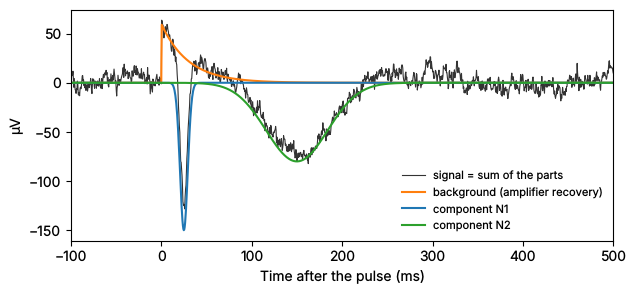

In [1]:
import numpy as np

import matplotlib.pyplot as plt

from evoparam import ResponseModel
from evoparam.shapes import get_shape
from evoparam.sim import make_noise, shape_params

sfreq = 2048.0
times = np.arange(-0.5, 1.0, 1 / sfreq)
gaussian = get_shape("gaussian")

truth = {"N1": (0.025, 0.010, -150.0), "N2": (0.150, 0.080, -80.0)}  # latency s, FWHM s, µV
components = {
    label: amp * gaussian.evaluate(times, shape_params("gaussian", lat, fwhm))
    for label, (lat, fwhm, amp) in truth.items()
}
background = np.where(times > 0, 60.0 * np.exp(-times / 0.030), 0.0)
noise = make_noise(times.size, sfreq, "pink", sd=8.0, seed=3)
y = background + sum(components.values()) + noise

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(times * 1000, y, color="0.2", lw=0.8, label="signal = sum of the parts")
ax.plot(times * 1000, background, color="tab:orange", label="background (amplifier recovery)")
for (label, part), color in zip(components.items(), ("tab:blue", "tab:green"), strict=True):
    ax.plot(times * 1000, part, color=color, label=f"component {label}")
ax.set(xlim=(-100, 500), xlabel="Time after the pulse (ms)", ylabel="µV")
ax.legend(frameon=False, fontsize=8)

## Fit it

A :class:`~evoparam.ResponseModel` holds the settings; the ``ccep`` preset sets them for cortico-cortical evoked potentials (fit window 9 to 500 ms, exponential background, up to 6 components). ``fit_waveform`` fits one curve and returns a ``ResponseFit``.

In [2]:
model = ResponseModel("ccep", random_state=0)
fit = model.fit_waveform(times, y)
print(fit.status)

ok


## What the fit found, next to the truth

One row per component found. ``latency`` and ``fwhm`` are in seconds, ``amplitude`` in µV; the ``_ci_low`` / ``_ci_high`` columns are 95 % intervals.

In [3]:
table = fit.to_dataframe()
print(
    table[["label", "latency", "amplitude", "fwhm", "latency_ci_low", "latency_ci_high"]].round(4)
)
print("truth:", truth)
print("background found:", {k: round(v, 4) for k, v in fit.background.items() if k != "name"})

  label  latency  amplitude    fwhm  latency_ci_low  latency_ci_high
0    N1   0.0250  -152.0527  0.0095          0.0247           0.0252
1    N2   0.1519   -77.4340  0.0792          0.1482           0.1556
truth: {'N1': (0.025, 0.01, -150.0), 'N2': (0.15, 0.08, -80.0)}
background found: {'c0': 2.5681, 'c1': 41.6602, 'tau': 0.0353, 't_ref': 0.0093}


## The fit, part by part

Data in grey, full model in black, background and each component in colour, and the residual (data minus model) below: it should look like the baseline noise.

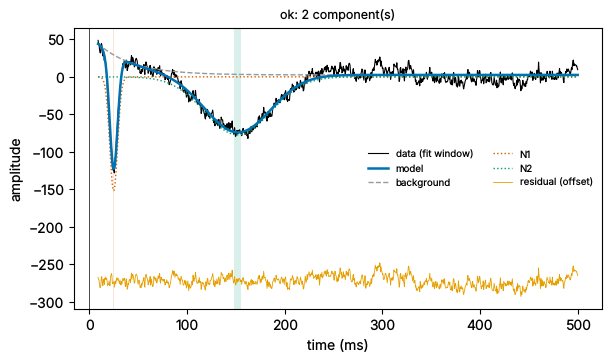

In [4]:
from evoparam import plots

fig = plots.plot_fit(fit)

## Remove the background, keep the components

As a power spectrum is flattened by removing its aperiodic part, the response is isolated by removing the fitted background: what is left is the components and the noise.

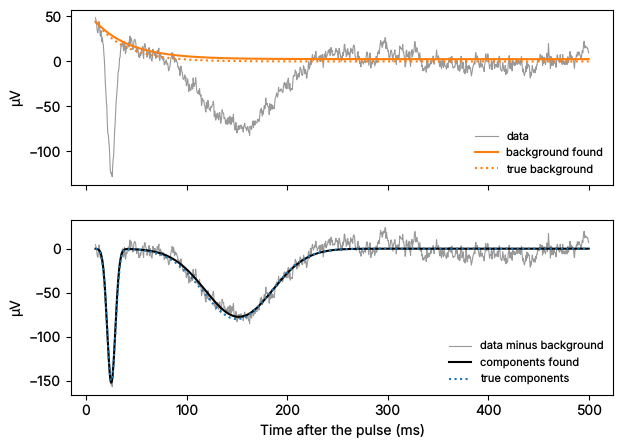

In [5]:
inside = (times >= fit.window[0]) & (times <= fit.window[1])
t_fit = times[inside]
found = [c.amplitude * get_shape(c.shape).evaluate(t_fit, c.params) for c in fit.components]
background_fit = fit.model - sum(found)

fig, (top, bottom) = plt.subplots(2, 1, figsize=(7, 5), sharex=True)
top.plot(t_fit * 1000, y[inside], color="0.6", lw=0.8, label="data")
top.plot(t_fit * 1000, background_fit, color="tab:orange", label="background found")
top.plot(t_fit * 1000, background[inside], color="tab:orange", ls=":", label="true background")
top.set(ylabel="µV")
top.legend(frameon=False, fontsize=8)
bottom.plot(
    t_fit * 1000, y[inside] - background_fit, color="0.6", lw=0.8, label="data minus background"
)
bottom.plot(t_fit * 1000, sum(found), color="k", label="components found")
bottom.plot(
    t_fit * 1000,
    sum(components.values())[inside],
    color="tab:blue",
    ls=":",
    label="true components",
)
bottom.set(xlabel="Time after the pulse (ms)", ylabel="µV")
bottom.legend(frameon=False, fontsize=8)

## Same response, other noise

The numbers above come from one draw of the noise. With five other draws the N1 latency stays within about 0.3 ms of the truth, while its amplitude moves by up to about 17 µV, and one draw adds a small extra bump near the end of the window: that spread is what the noise allows, and the 95 % intervals say how large it is.

In [6]:
import pandas as pd

rows = []
for seed in range(5):
    y_other = (
        background
        + sum(components.values())
        + make_noise(times.size, sfreq, "pink", sd=8.0, seed=seed)
    )
    for c in model.fit_waveform(times, y_other).components:
        rows.append(
            {
                "noise draw": seed,
                "label": c.label,
                "latency_ms": 1000 * c.latency,
                "amplitude_uV": c.amplitude,
                "fwhm_ms": 1000 * c.fwhm,
            }
        )
print(pd.DataFrame(rows).round(1).to_string(index=False))

 noise draw     label  latency_ms  amplitude_uV  fwhm_ms
          0        N1        25.1        -166.6     10.1
          0        N2       145.3         -68.7     82.1
          1        N1        25.1        -146.8      9.6
          1        N2       153.3         -80.5     90.0
          2        N1        24.8        -148.7     10.1
          2        N2       149.4         -82.8     86.8
          2 delayed_b       483.8          16.9     26.0
          3        N1        25.0        -152.1      9.5
          3        N2       151.9         -77.4     79.2
          4        N1        25.0        -142.1      9.8
          4        N2       150.4         -79.7     70.2


## The methods paragraph

Every fit can write the paragraph that describes how it was obtained, for a paper.

In [7]:
print(fit.methods_text())

Evoked responses were analysed with evoparam (version 0.1.0.dev0) using the preset 'ccep' v1.1; validation: ds004080 (REQ-113, REQ-114, REQ-135). In the window 9 to 500 ms, each waveform was modelled as an exponential background plus up to 6 components (skewed gaussian and gaussian; full width at half maximum 3 to 250 ms, both polarities). Amplitudes and background coefficients were solved by variable projection and the other parameters by bounded least squares (linear loss, 3 starts). Components were added one at a time and kept when the BIC decreased by at least 10, computed on residuals whitened by an autoregressive model of the noise of the baseline. A final model holding two overlapping components of opposite sign was refitted from starts on the extrema of the data and replaced when the refit was better; a component of the refitted model that no longer lowered the criterion by the same amount was removed. Uncertainty: Jacobian-based (Wald) intervals at 95 %. Onset and offset are t